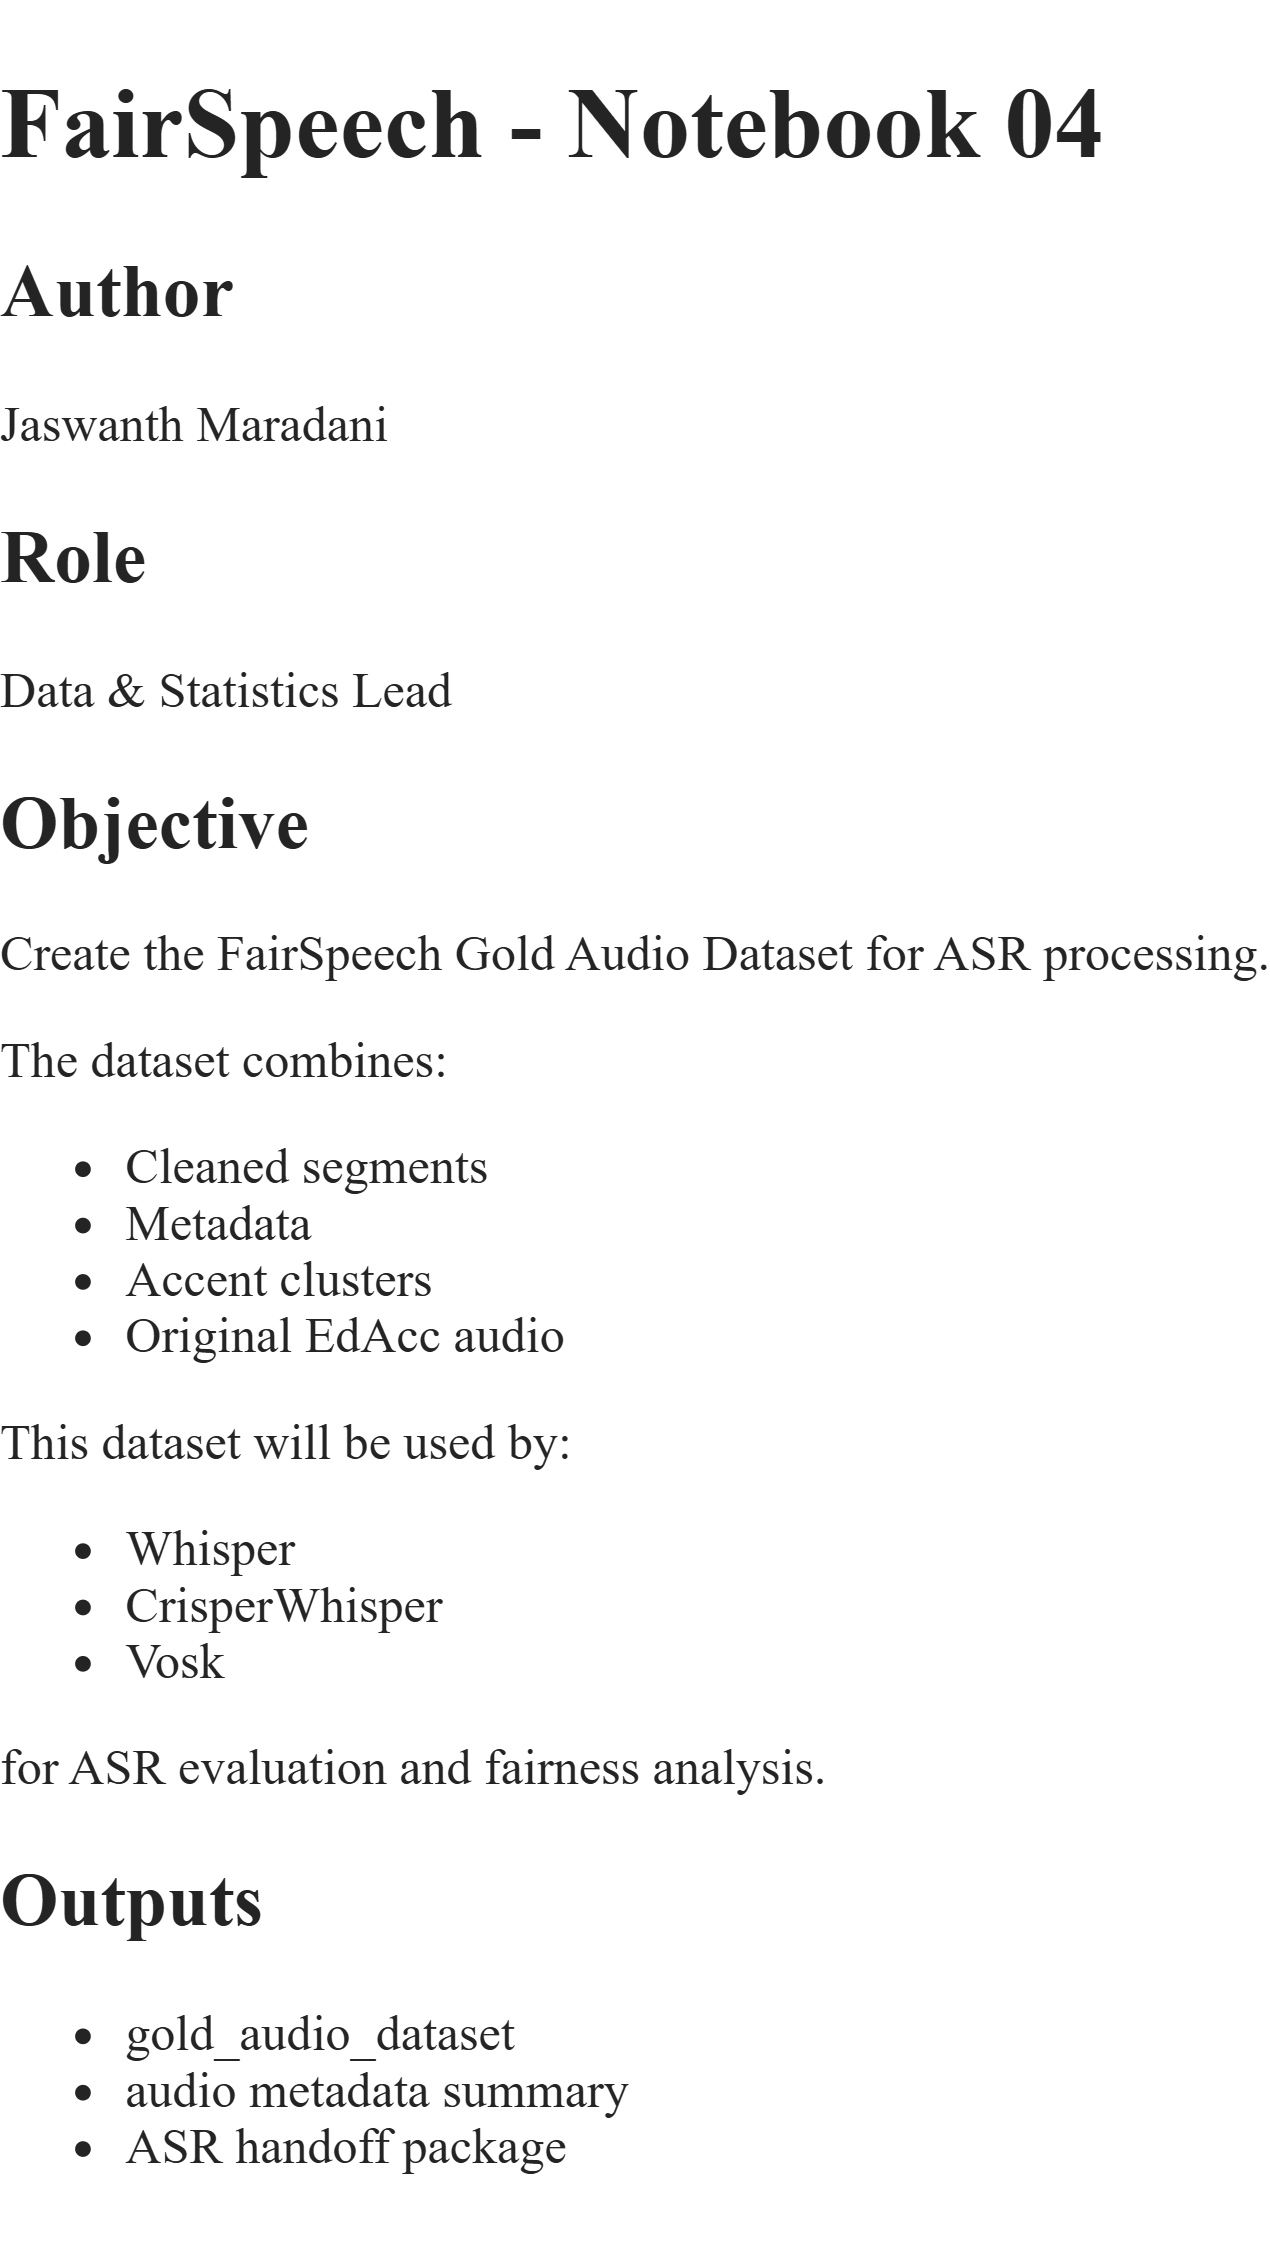

In [ ]:
from datasets import load_dataset
import pandas as pd
import numpy as np

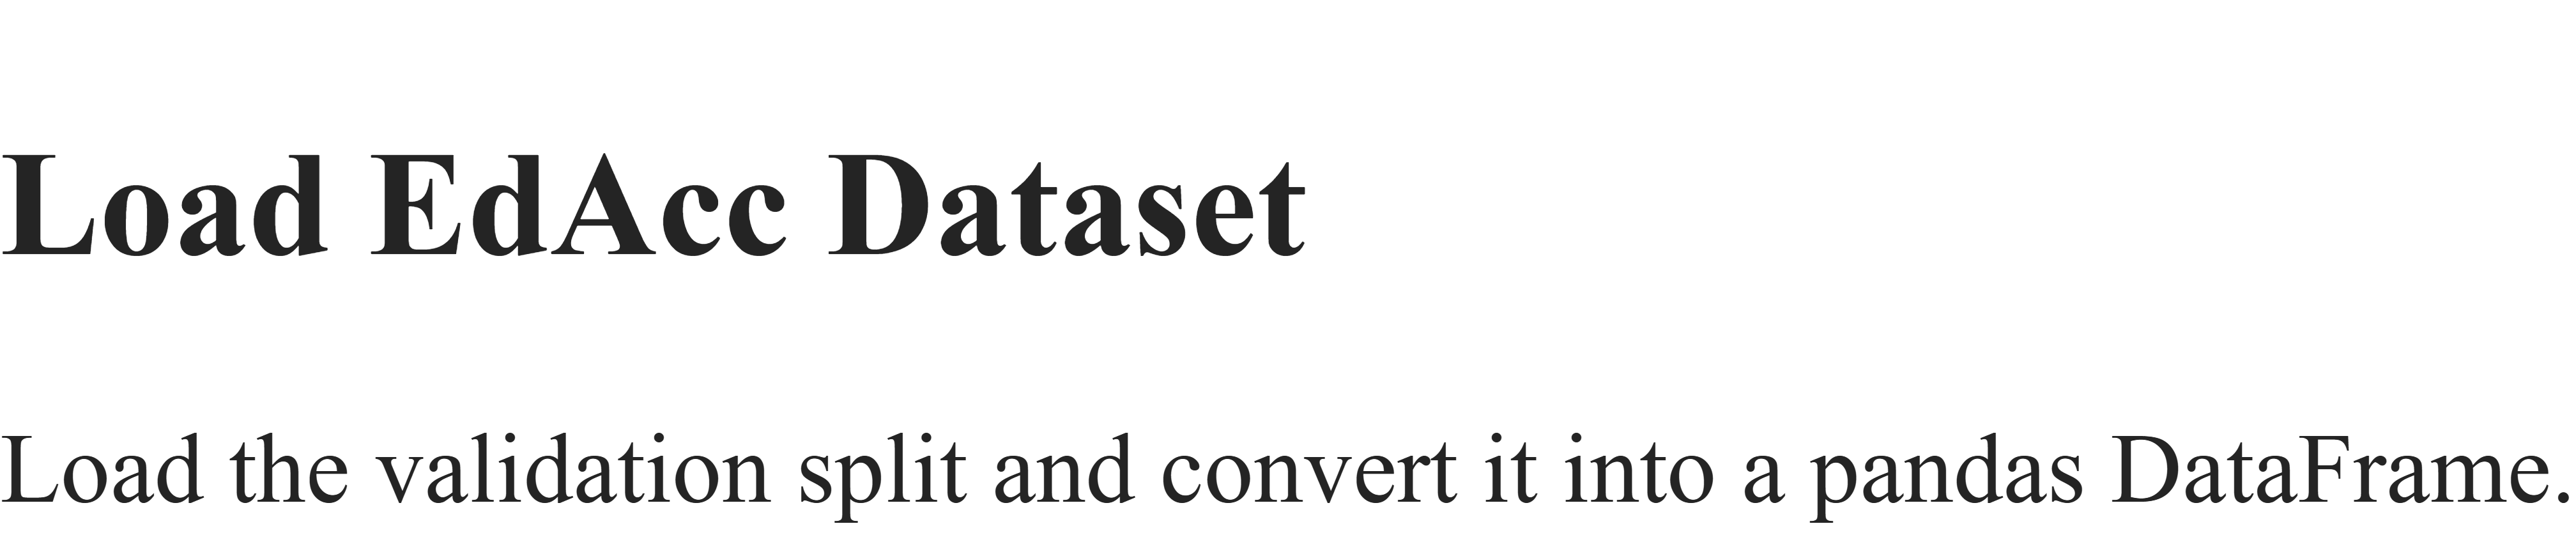

In [ ]:
edacc = load_dataset(
    "edinburghcstr/edacc"
)

df = pd.DataFrame(
    edacc["validation"]
)

print(df.shape)

README.md:   0%|          | 0.00/6.95k [00:00<?, ?B/s]

data/validation-00000-of-00006-17ec18f4d(…): reconstructing file:   0%|          |  0.00B /  457MB            

data/validation-00000-of-00006-17ec18f4d(…): downloading bytes:           |  0.00B            

data/validation-00001-of-00006-6f3978e4f(…): reconstructing file:   0%|          |  0.00B /  478MB            

data/validation-00001-of-00006-6f3978e4f(…): downloading bytes:           |  0.00B            

data/validation-00002-of-00006-5a1d86079(…): reconstructing file:   0%|          |  0.00B /  446MB            

... (26 outputs left out)

data/test-00009-of-00010-648ce5002d12449(…): downloading bytes:           |  0.00B            

Generating validation split:   0%|          | 0/9848 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/9289 [00:00<?, ? examples/s]

(9848, 7)


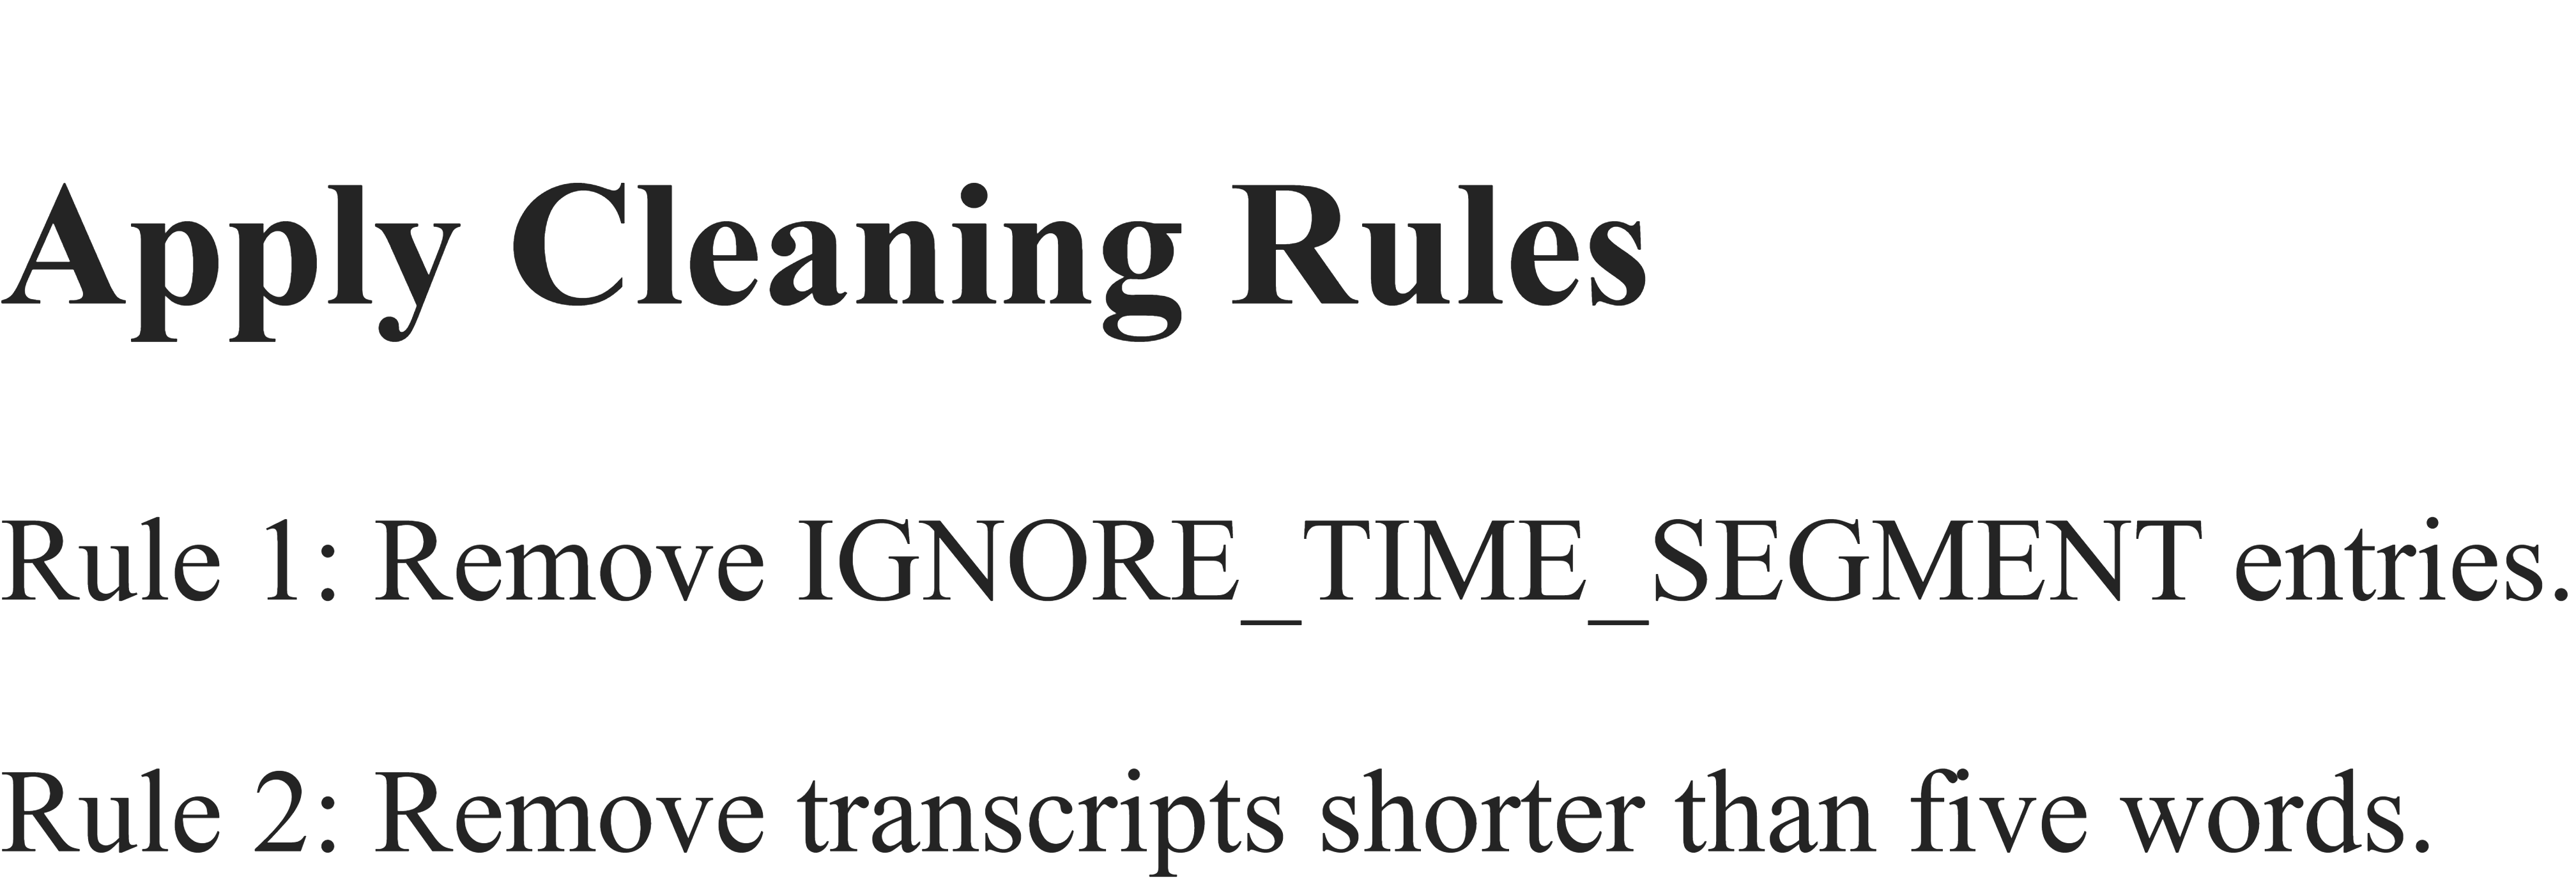

In [ ]:
df_clean = df[
    ~df["text"].str.contains(
        "IGNORE_TIME_SEGMENT",
        na=False
    )
].copy()

df_clean["word_count"] = (
    df_clean["text"]
    .apply(lambda x: len(str(x).split()))
)

df_clean = df_clean[
    df_clean["word_count"] >= 5
]

print(df_clean.shape)

(5871, 8)


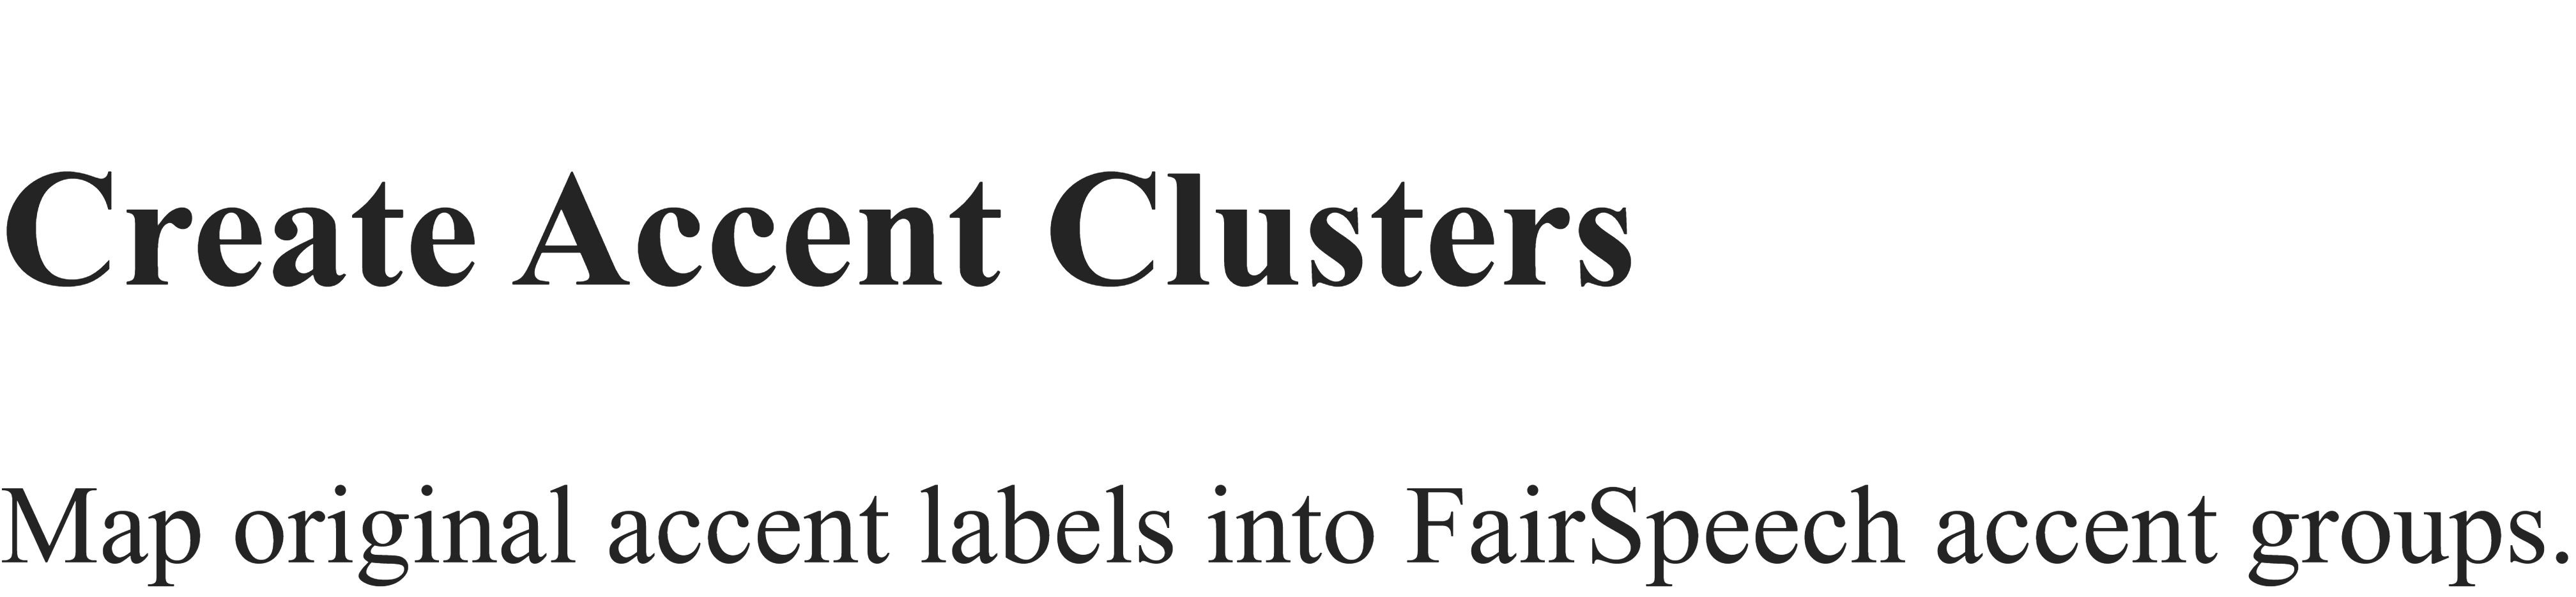

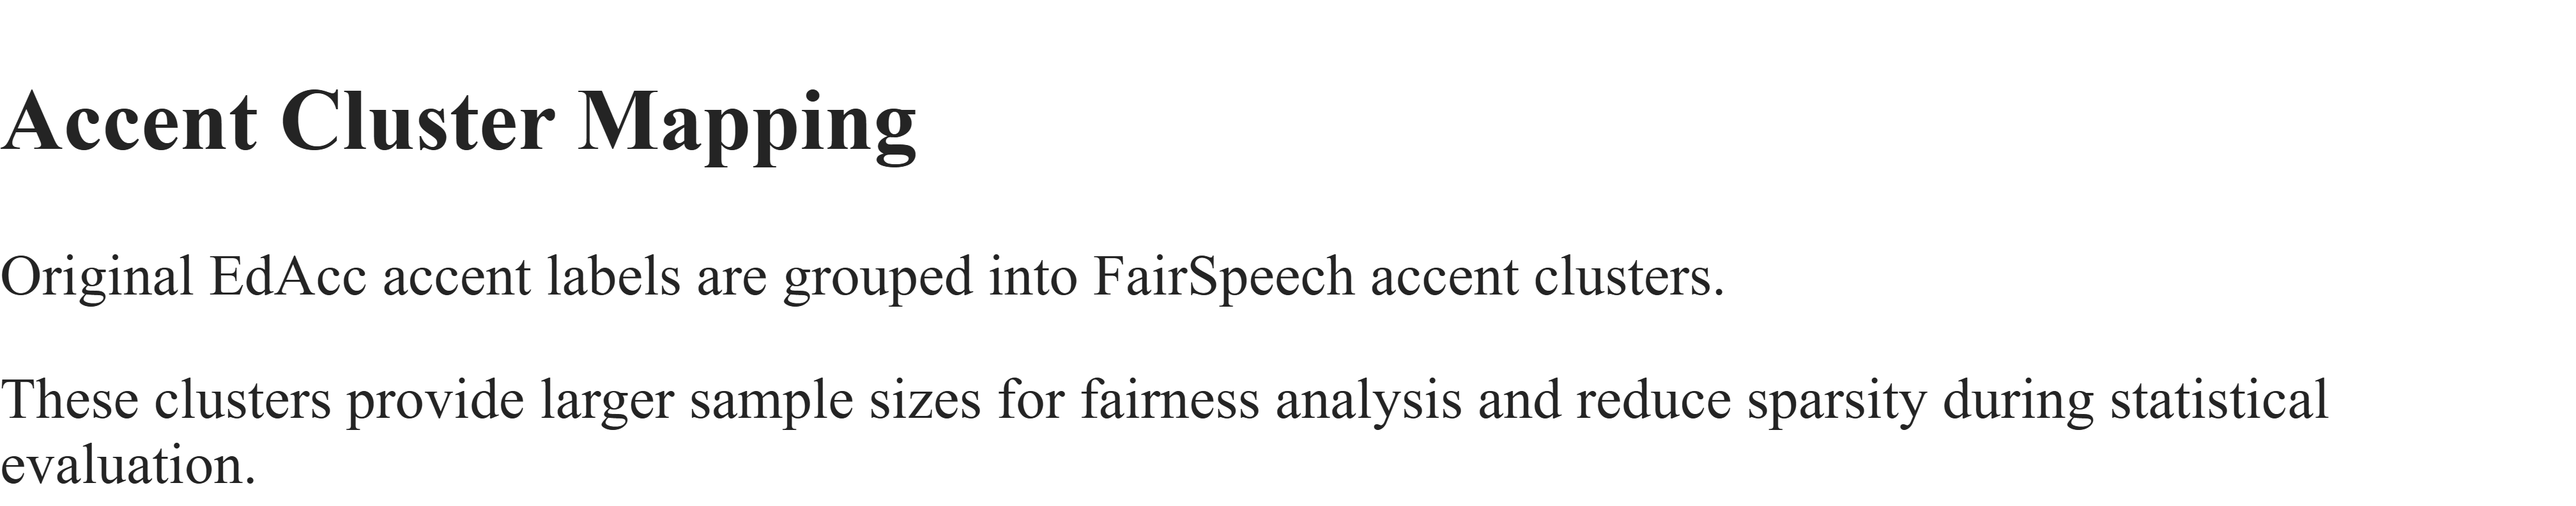

In [ ]:
accent_mapping = {
    "Southern British English": "Native",
    "Mainstream US English": "Native",
    "Irish English": "Native",
    "Scottish English": "Native",

    "Indian English": "South Asian",

    "Jamaican English": "Caribbean",

    "South African English": "African",

    "Italian": "European",
    "Spanish": "European",
    "Catalan": "European",
    "Bulgarian": "European",
    "German": "European",
    "French": "European",

    "Chinese": "East Asian",
    "Japanese": "East Asian",
    "Vietnamese": "East Asian",

    "Egyptian": "Middle Eastern"
}

In [ ]:
df_clean["accent_cluster"] = (
    df_clean["accent"]
    .map(accent_mapping)
)

df_clean["segment_id"] = (
    "SEG_" +
    df_clean.index.astype(str)
)

print(
    "Accent clusters created successfully"
)

print(
    df_clean["accent_cluster"]
    .value_counts(dropna=False)
)

Accent clusters created successfully
accent_cluster
Native            2213
NaN               1364
European           901
East Asian         541
Middle Eastern     283
South Asian        204
Caribbean          201
African            164
Name: count, dtype: int64


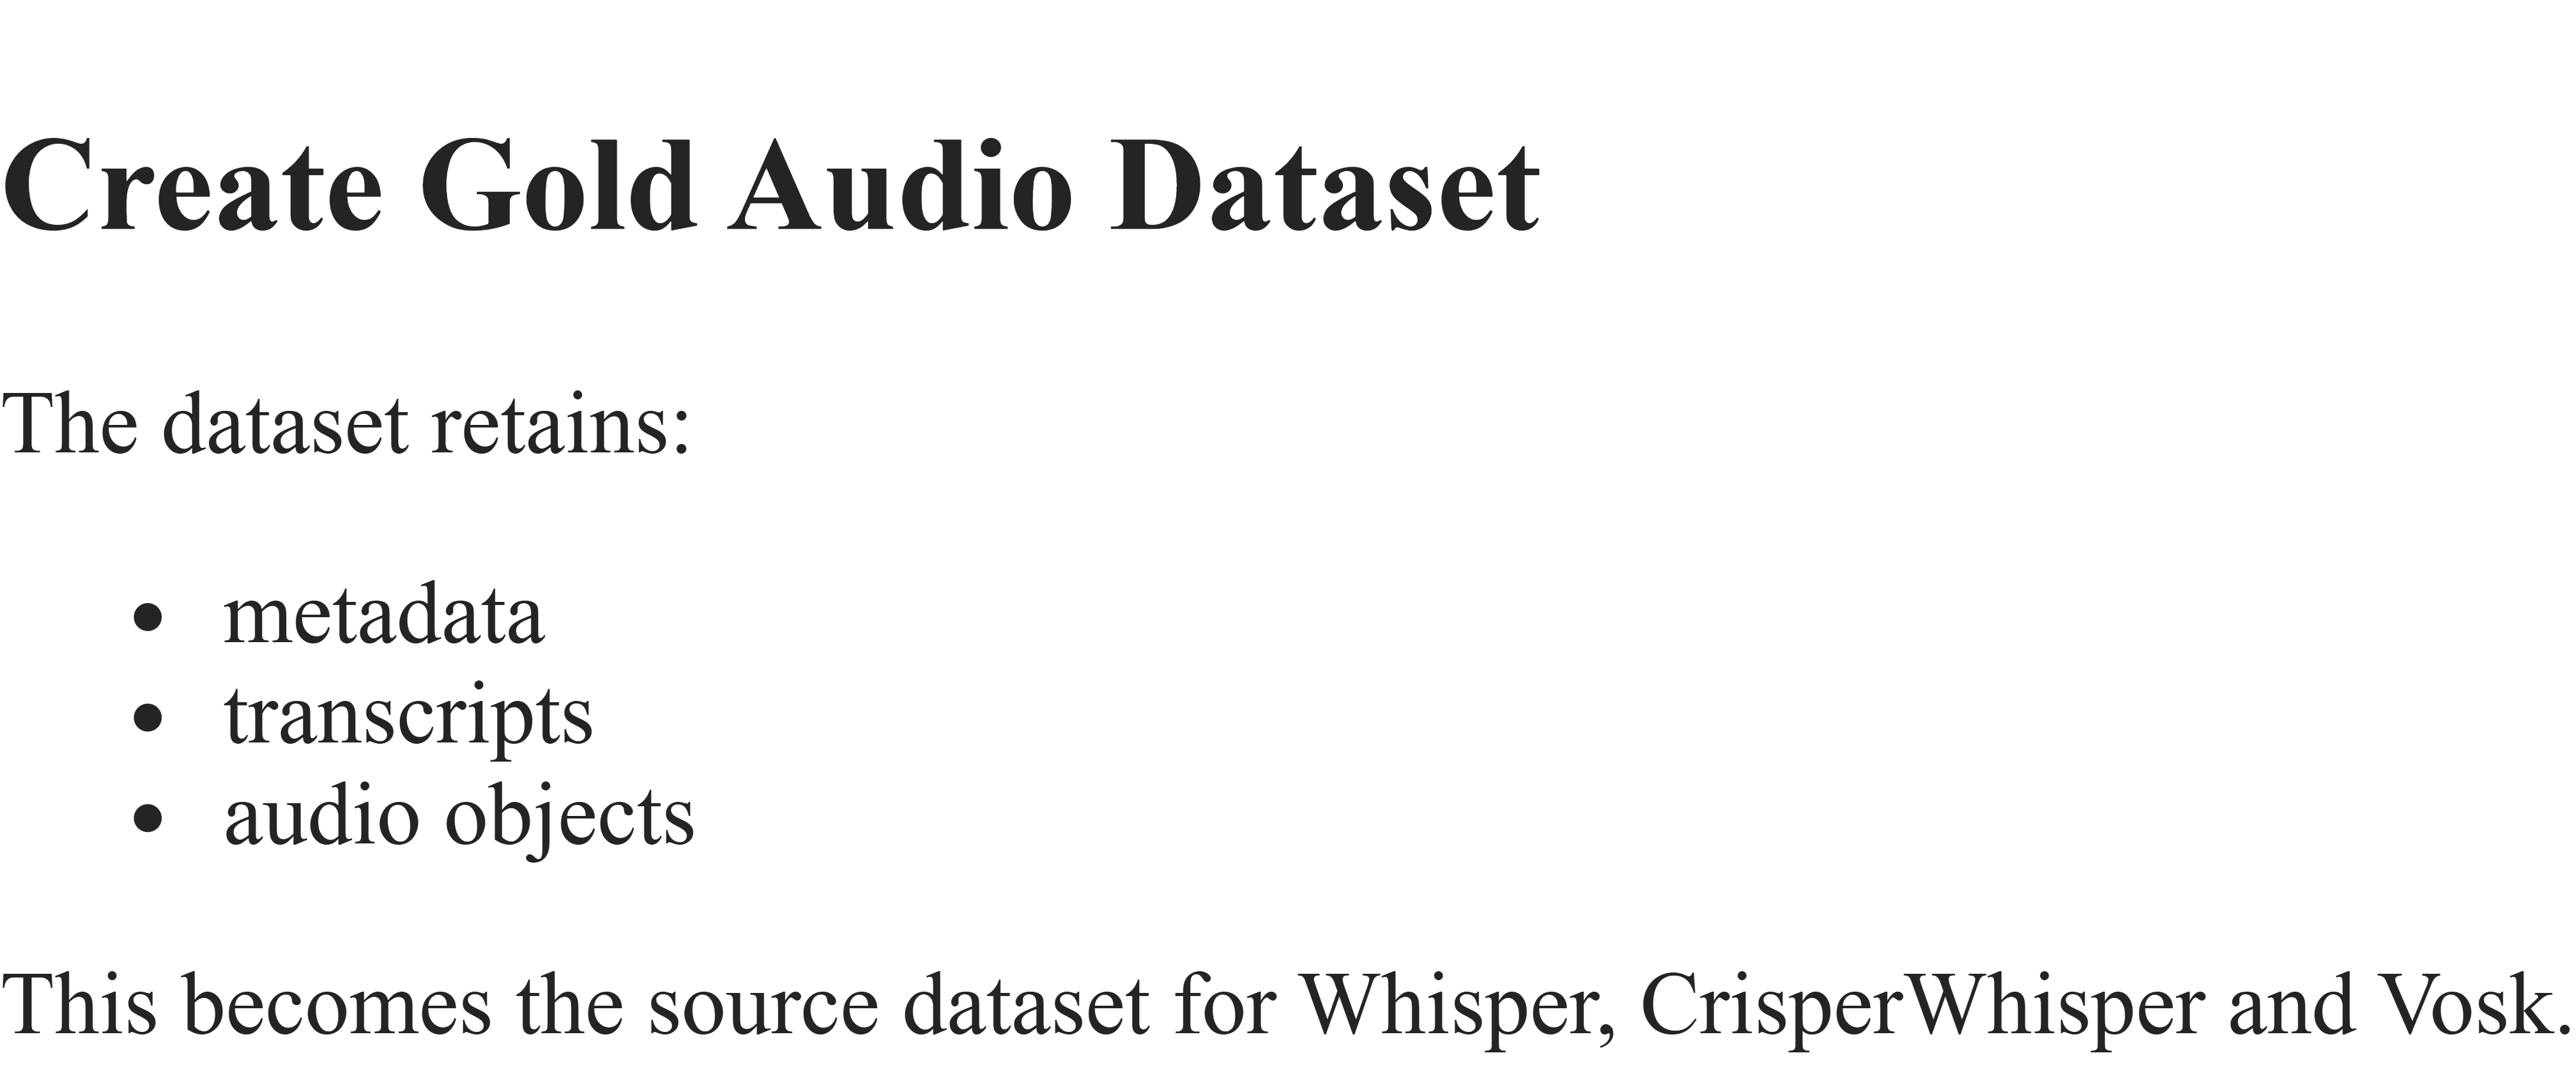

In [ ]:
gold_audio_df = df_clean[
    [
        "segment_id",
        "speaker",
        "accent",
        "accent_cluster",
        "l1",
        "word_count",
        "text",
        "audio"
    ]
].copy()

print(gold_audio_df.shape)

(5871, 8)


In [ ]:
print(type(gold_audio_df.iloc[0]["audio"]))

<class 'datasets.features._torchcodec.AudioDecoder'>


In [ ]:
sample_audio = gold_audio_df.iloc[0]["audio"]

print(sample_audio)


In [ ]:
sample_audio = gold_audio_df.iloc[0]["audio"]

dir(sample_audio)

['__class__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__firstlineno__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getitem__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__sizeof__',
 '__static_attributes__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 '_decoder',
 '_desired_sample_rate',
 '_hf_encoded',
 'get_all_samples',
 'get_samples_played_in_range',
 'metadata',
 'stream_index']

In [ ]:
print(sample_audio.metadata)

AudioStreamMetadata:
  duration_seconds_from_header: 5.27
  begin_stream_seconds_from_header: None
  bit_rate: 512000
  codec: pcm_s16le
  stream_index: 0
  media_type: audio
  sample_rate: 32000
  num_channels: 1
  sample_format: s16
  duration_seconds: 5.27
  begin_stream_seconds: 0



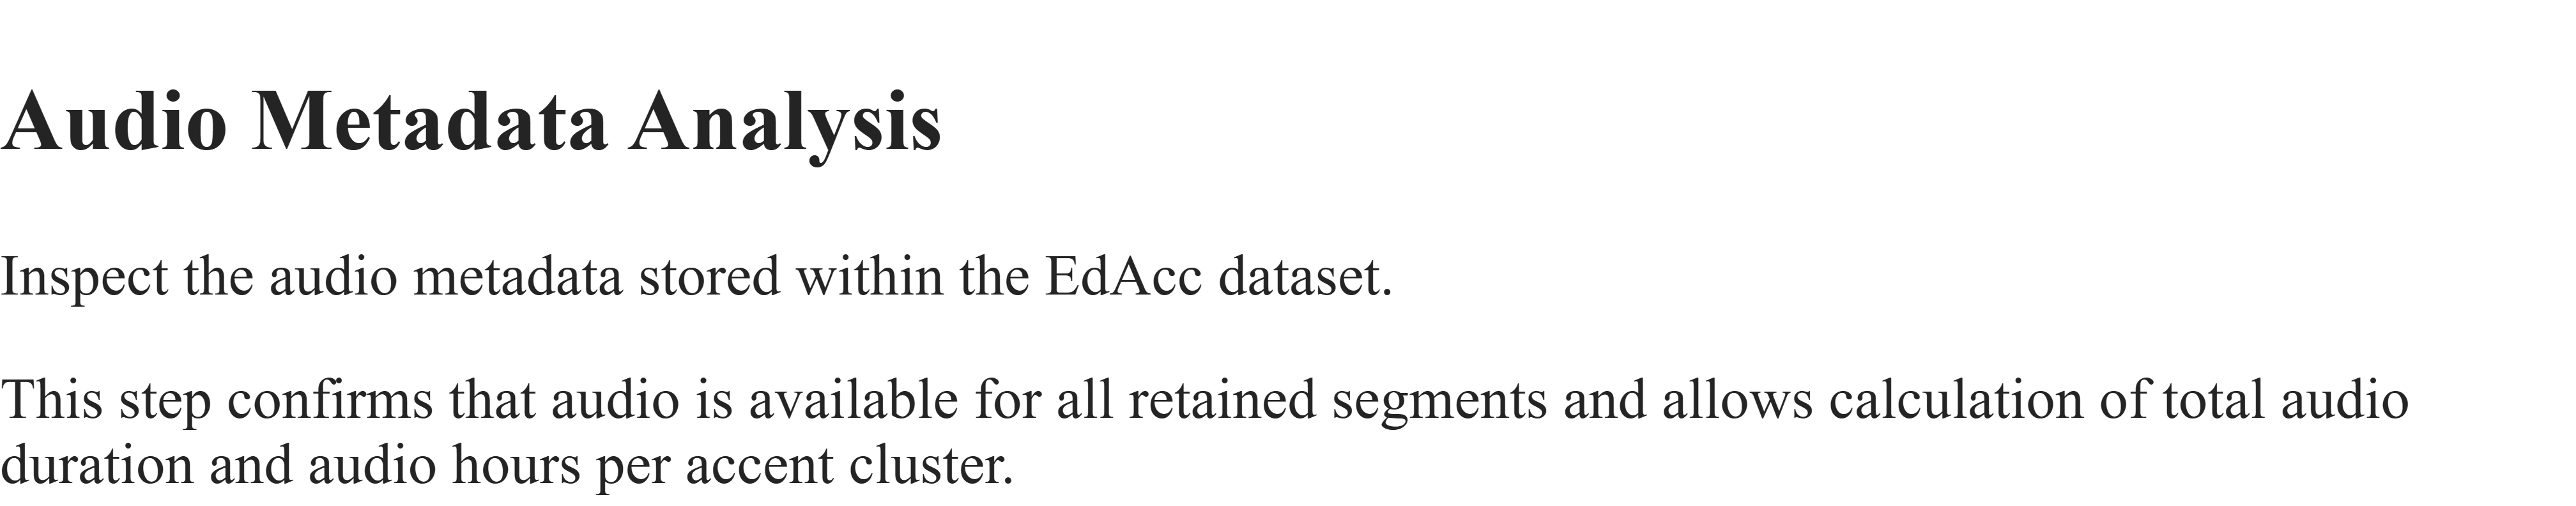

In [ ]:
gold_audio_df["duration_sec"] = (
    gold_audio_df["audio"]
    .apply(
        lambda x: x.metadata.duration_seconds
    )
)

gold_audio_df[
    [
        "segment_id",
        "duration_sec"
    ]
].head()

,segment_id,duration_sec
0,SEG_0,5.27
1,SEG_1,2.08
4,SEG_4,8.35
5,SEG_5,4.18
6,SEG_6,8.38


In [ ]:
gold_audio_df["duration_sec"].describe()

,duration_sec
count,5871.00000
mean,8.92453
std,11.22213
min,0.37000
25%,2.84500
50%,5.44000
75%,10.48000
max,143.38000


In [ ]:
total_hours = (
    gold_audio_df["duration_sec"]
    .sum()
    / 3600
)

print(
    f"Total Audio Hours: {total_hours:.2f}"
)

Total Audio Hours: 14.55


In [ ]:
cluster_hours = (
    gold_audio_df
    .groupby("accent_cluster")
    ["duration_sec"]
    .sum()
    / 3600
)

print(cluster_hours)

accent_cluster
African           0.546014
Caribbean         0.404228
East Asian        1.366517
European          2.844718
Middle Eastern    1.049647
Native            5.141610
South Asian       0.301375
Name: duration_sec, dtype: float64


In [ ]:
audio_summary = (
    gold_audio_df
    .groupby("accent_cluster")
    .agg(
        segments=("segment_id", "count"),
        speakers=("speaker", "nunique"),
        total_hours=("duration_sec",
                     lambda x: x.sum()/3600)
    )
)

audio_summary

,segments,speakers,total_hours
accent_cluster,,,
African,164,2,0.546014
Caribbean,201,2,0.404228
East Asian,541,7,1.366517
European,901,12,2.844718
Middle Eastern,283,2,1.049647
Native,2213,23,5.141610
South Asian,204,2,0.301375


In [ ]:
audio_summary.to_csv(
    "audio_cluster_summary.csv"
)

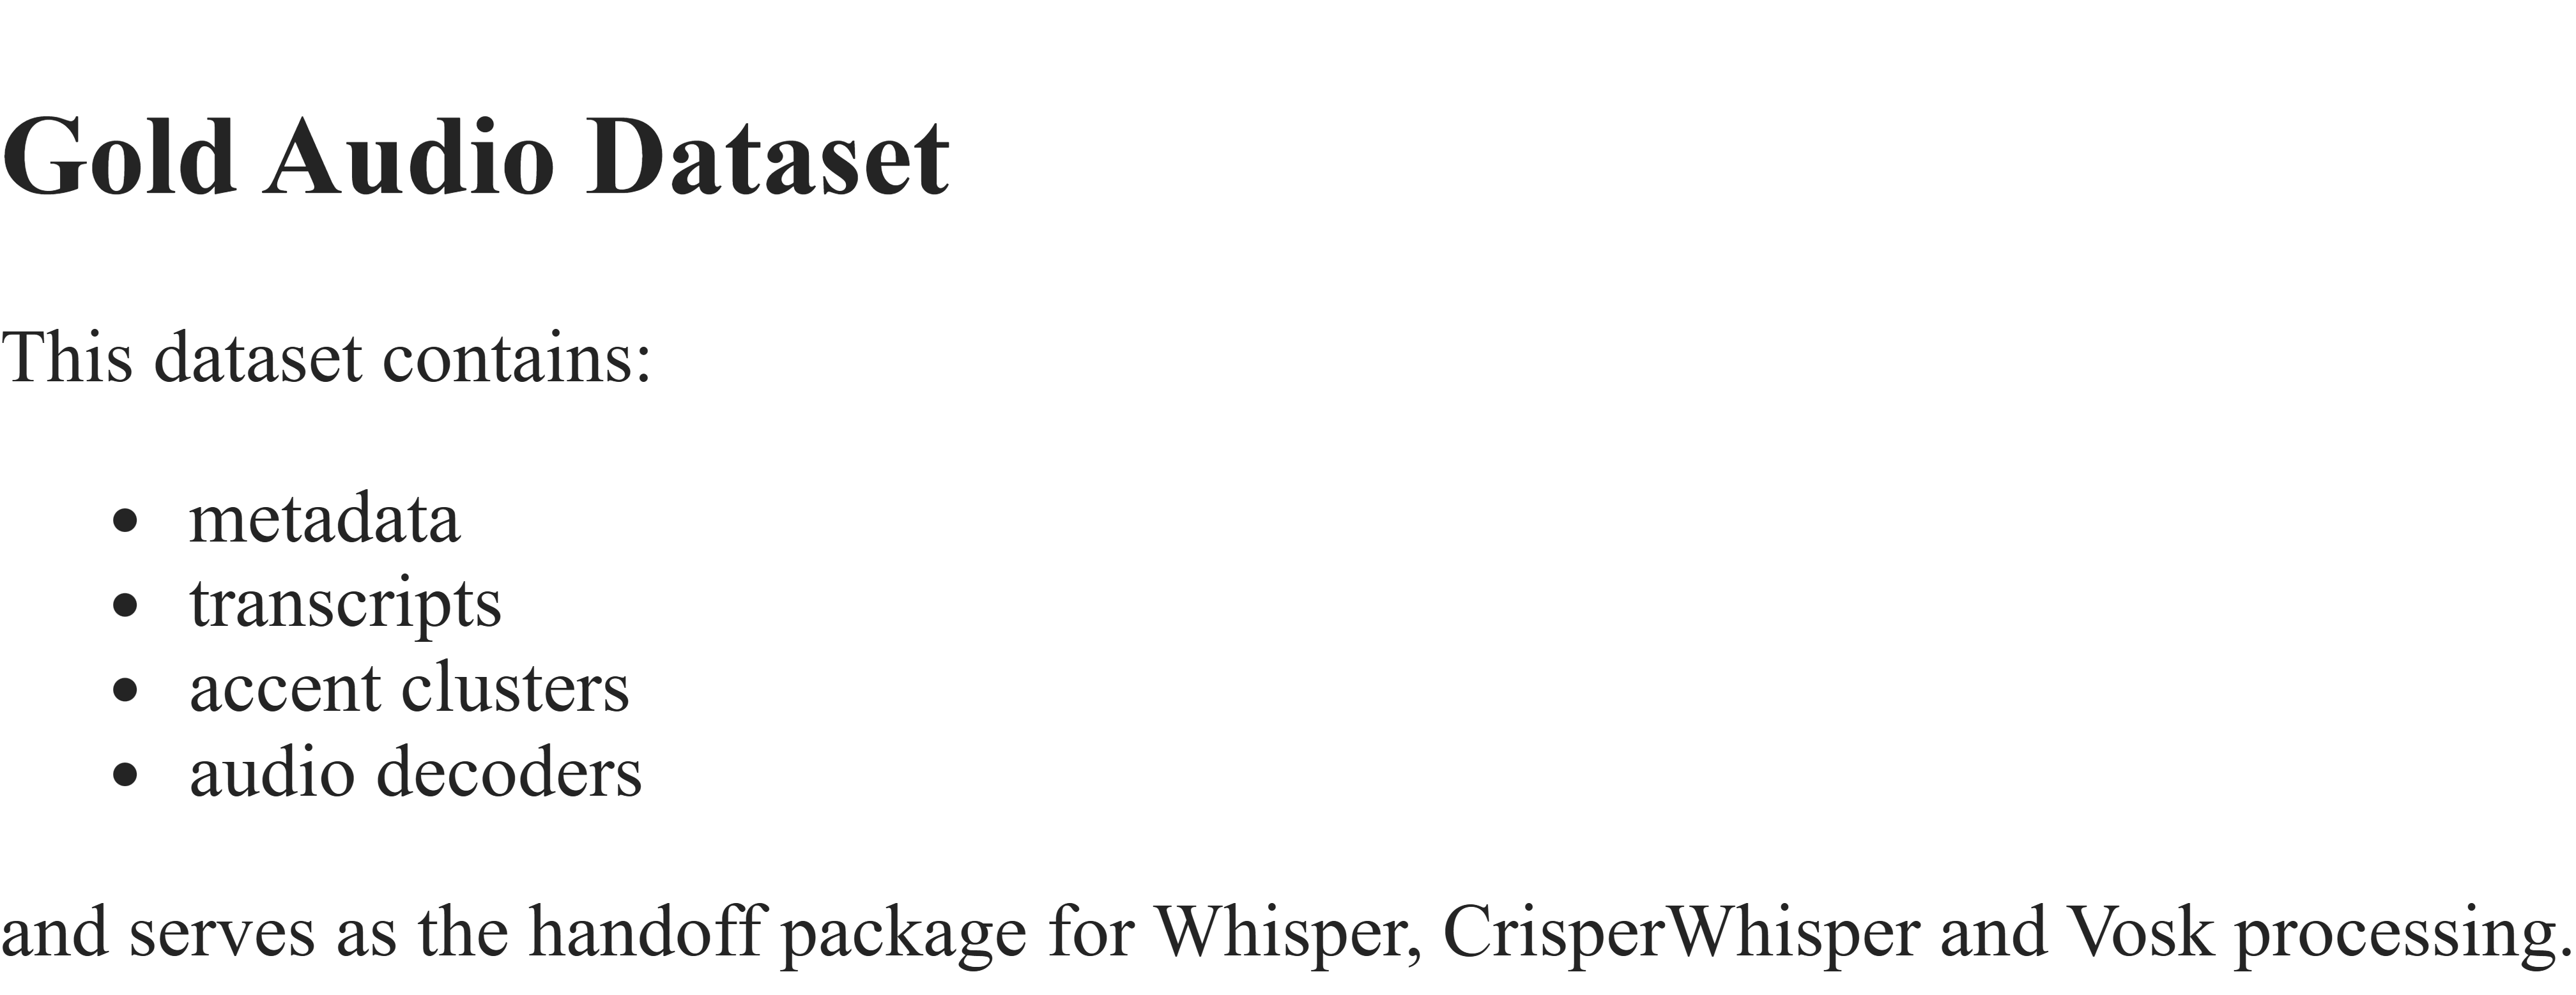

In [ ]:
gold_audio_df.to_pickle(
    "gold_audio_dataset.pkl"
)

print(
    "Gold Audio Dataset saved successfully."
)

Gold Audio Dataset saved successfully.


In [ ]:
loaded_audio = pd.read_pickle(
    "gold_audio_dataset.pkl"
)

print(
    loaded_audio.shape
)

(5871, 9)


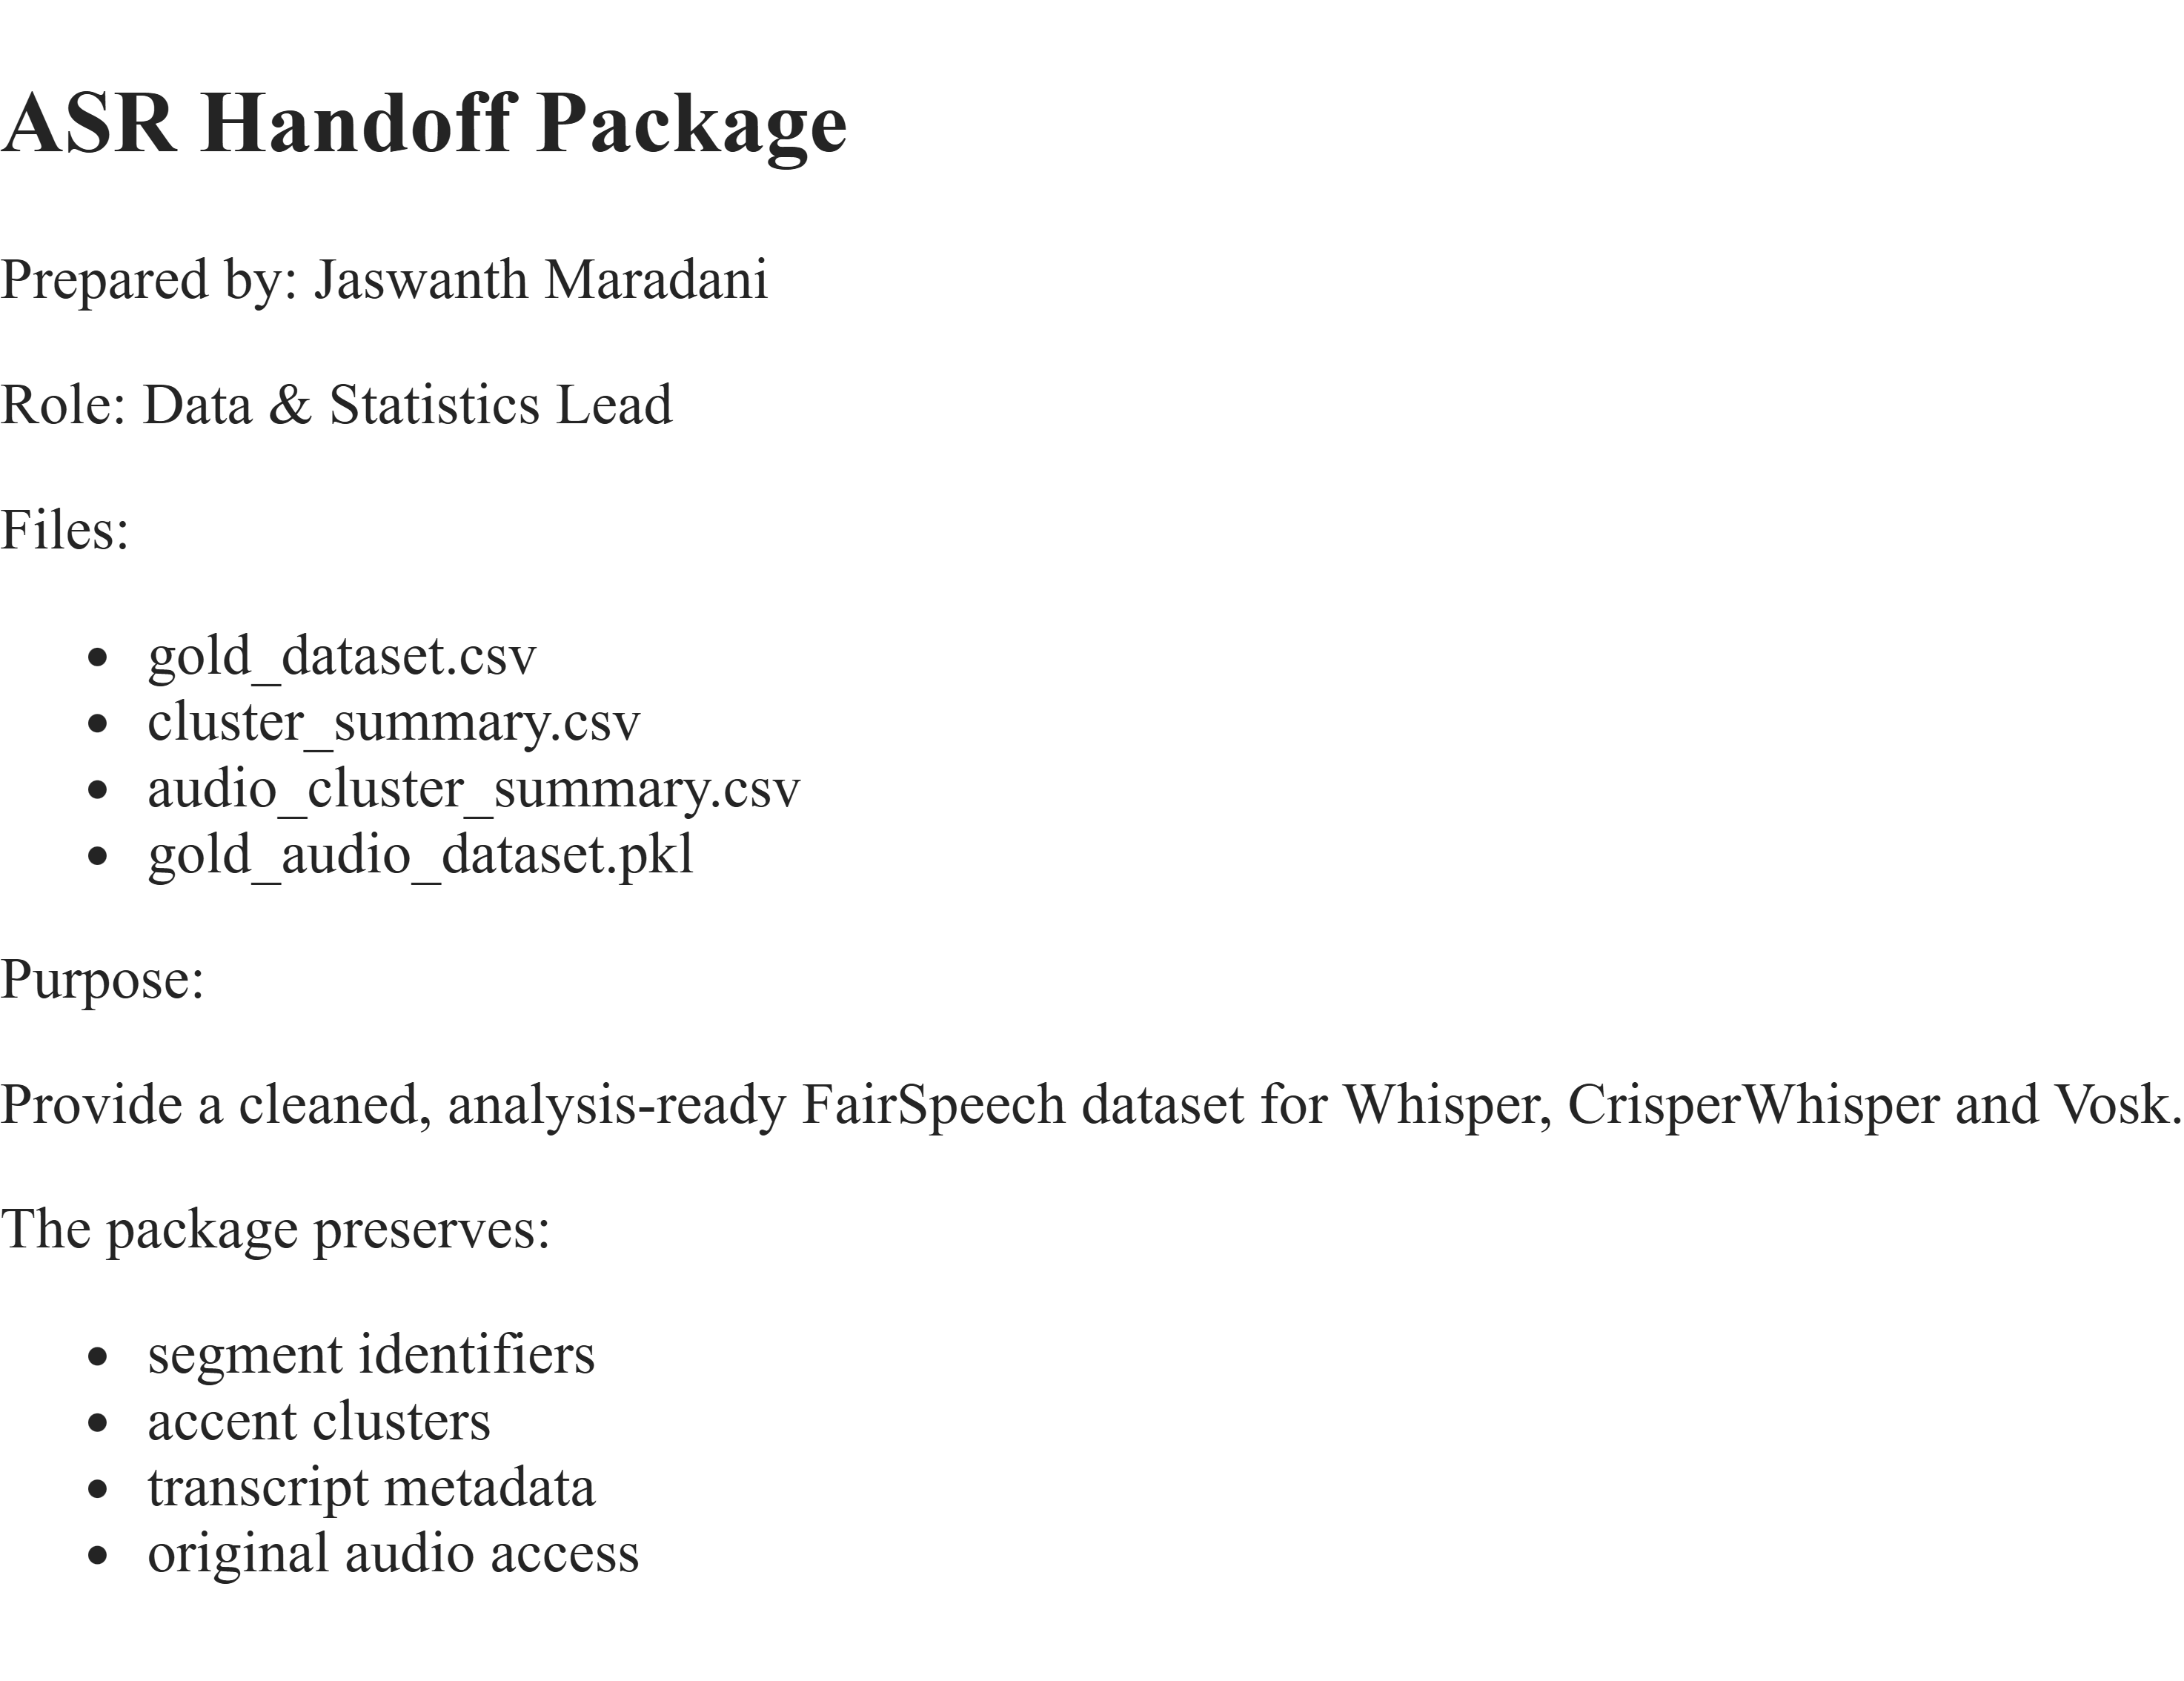

In [20]:
import os

size_mb = os.path.getsize(
    "gold_audio_dataset.pkl"
) / (1024 * 1024)

print(
    f"File Size: {size_mb:.2f} MB"
)

File Size: 3202.65 MB


In [21]:
gold_audio_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5871 entries, 0 to 9844
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   segment_id      5871 non-null   object 
 1   speaker         5871 non-null   object 
 2   accent          5871 non-null   object 
 3   accent_cluster  4507 non-null   object 
 4   l1              5871 non-null   object 
 5   word_count      5871 non-null   int64  
 6   text            5871 non-null   object 
 7   audio           5871 non-null   object 
 8   duration_sec    5871 non-null   float64
dtypes: float64(1), int64(1), object(7)
memory usage: 458.7+ KB


In [22]:
gold_audio_df.columns

Index(['segment_id', 'speaker', 'accent', 'accent_cluster', 'l1', 'word_count',
       'text', 'audio', 'duration_sec'],
      dtype='object')

In [23]:
print(
    f"Total Hours: {total_hours:.2f}"
)

audio_summary

Total Hours: 14.55


,segments,speakers,total_hours
accent_cluster,,,
African,164,2,0.546014
Caribbean,201,2,0.404228
East Asian,541,7,1.366517
European,901,12,2.844718
Middle Eastern,283,2,1.049647
Native,2213,23,5.141610
South Asian,204,2,0.301375
